In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.10.0
NumPy: 1.26.4


In [34]:
# 8 × 8 фізичних квадратів
# => 7 × 7 внутрішніх кутів
CHECKERBOARD = (7, 9)

# Розмір одного квадрата в міліметрах
SQUARE_SIZE = 20.0

# Папка з фотографіями шахівниці
IMAGE_DIR = "calibration_images"

# Розширення фотографій
IMAGE_EXTENSIONS = ("*.jpg", "*.jpeg", "*.png")

print("Checkerboard:", CHECKERBOARD)
print("Square size:", SQUARE_SIZE, "mm")

Checkerboard: (7, 9)
Square size: 20.0 mm


In [35]:
images = []

for ext in IMAGE_EXTENSIONS:
    images.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

images = sorted(images)

print(f"Знайдено фотографій: {len(images)}")

for image_path in images:
    print(image_path)

Знайдено фотографій: 24
calibration_images/PXL_20261008_131316787.MP.jpg
calibration_images/PXL_20261008_131320964.MP.jpg
calibration_images/PXL_20261008_131326200.MP.jpg
calibration_images/PXL_20261008_131330469.MP.jpg
calibration_images/PXL_20261008_131333103.MP.jpg
calibration_images/PXL_20261008_131338920.MP.jpg
calibration_images/PXL_20261008_131341016.MP.jpg
calibration_images/PXL_20261008_131344365.MP.jpg
calibration_images/PXL_20261008_131350692.MP.jpg
calibration_images/PXL_20261008_131354601.MP.jpg
calibration_images/PXL_20261008_131400212.MP.jpg
calibration_images/PXL_20261008_131405366.MP.jpg
calibration_images/PXL_20261008_131408764.MP.jpg
calibration_images/PXL_20261008_131413241.MP.jpg
calibration_images/PXL_20261008_131417228.MP.jpg
calibration_images/PXL_20261008_131423235.MP.jpg
calibration_images/PXL_20261008_131429038.MP.jpg
calibration_images/PXL_20261008_131431148.MP.jpg
calibration_images/PXL_20261008_131432769.MP.jpg
calibration_images/PXL_20261008_131438093.MP.

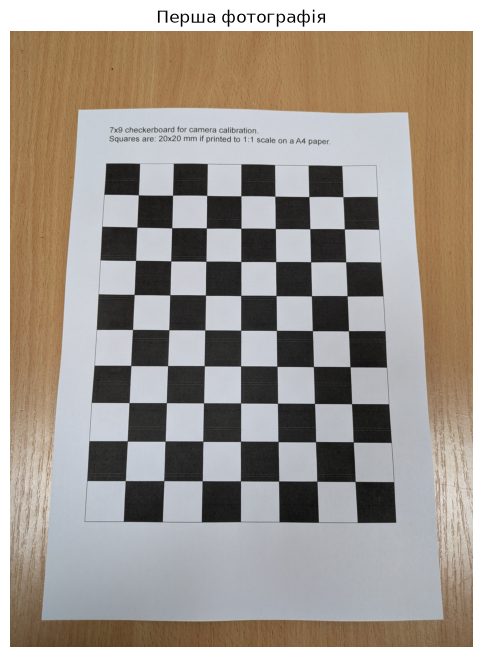

In [39]:
img = cv2.imread(images[0])

if img is None:
    raise ValueError(f"Не вдалося відкрити: {images[0]}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Перша фотографія")
plt.show()

In [40]:
#створення 3D координат шахівниці

objp = np.zeros(
    (CHECKERBOARD[0] * CHECKERBOARD[1], 3),
    np.float32
)

objp[:, :2] = np.mgrid[
    0:CHECKERBOARD[0],
    0:CHECKERBOARD[1]
].T.reshape(-1, 2)

# Переводимо одиниці в міліметри
objp *= SQUARE_SIZE

print("Кількість точок:", len(objp))
print("Перші точки:")
print(objp[:10])

Кількість точок: 63
Перші точки:
[[  0.   0.   0.]
 [ 20.   0.   0.]
 [ 40.   0.   0.]
 [ 60.   0.   0.]
 [ 80.   0.   0.]
 [100.   0.   0.]
 [120.   0.   0.]
 [  0.  20.   0.]
 [ 20.  20.   0.]
 [ 40.  20.   0.]]


In [43]:
# масиви для калібрування

objpoints = []  # 3D точки
imgpoints = []  # 2D точки

successful_images = []
failed_images = []

In [44]:
# пошук кутів шахівниці

for image_path in images:

    img = cv2.imread(image_path)

    if img is None:
        print(f"Не вдалося відкрити: {image_path}")
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(
        gray,
        CHECKERBOARD,
        None
    )

    if ret:
        objpoints.append(objp.copy())
        imgpoints.append(corners)
        successful_images.append(image_path)

        print("OK:", image_path)

    else:
        failed_images.append(image_path)
        print("FAIL:", image_path)

print()
print("Успішно:", len(successful_images))
print("Помилок:", len(failed_images))

OK: calibration_images/PXL_20261008_131316787.MP.jpg
OK: calibration_images/PXL_20261008_131320964.MP.jpg
OK: calibration_images/PXL_20261008_131326200.MP.jpg
OK: calibration_images/PXL_20261008_131330469.MP.jpg
OK: calibration_images/PXL_20261008_131333103.MP.jpg
OK: calibration_images/PXL_20261008_131338920.MP.jpg
OK: calibration_images/PXL_20261008_131341016.MP.jpg
OK: calibration_images/PXL_20261008_131344365.MP.jpg
OK: calibration_images/PXL_20261008_131350692.MP.jpg
OK: calibration_images/PXL_20261008_131354601.MP.jpg
OK: calibration_images/PXL_20261008_131400212.MP.jpg
OK: calibration_images/PXL_20261008_131405366.MP.jpg
OK: calibration_images/PXL_20261008_131408764.MP.jpg
OK: calibration_images/PXL_20261008_131413241.MP.jpg
OK: calibration_images/PXL_20261008_131417228.MP.jpg
OK: calibration_images/PXL_20261008_131423235.MP.jpg
OK: calibration_images/PXL_20261008_131429038.MP.jpg
OK: calibration_images/PXL_20261008_131431148.MP.jpg
OK: calibration_images/PXL_20261008_131432769.

In [46]:
# покращення точності координат

criteria = (
    cv2.TERM_CRITERIA_EPS +
    cv2.TERM_CRITERIA_MAX_ITER,
    30,
    0.001
)

refined_imgpoints = []

for image_path in successful_images:

    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(
        gray,
        CHECKERBOARD,
        None
    )

    if ret:

        corners_refined = cv2.cornerSubPix(
            gray,
            corners,
            (11, 11),
            (-1, -1),
            criteria
        )

        refined_imgpoints.append(corners_refined)

imgpoints = refined_imgpoints

print("Уточнено фотографій:", len(imgpoints))

Уточнено фотографій: 24


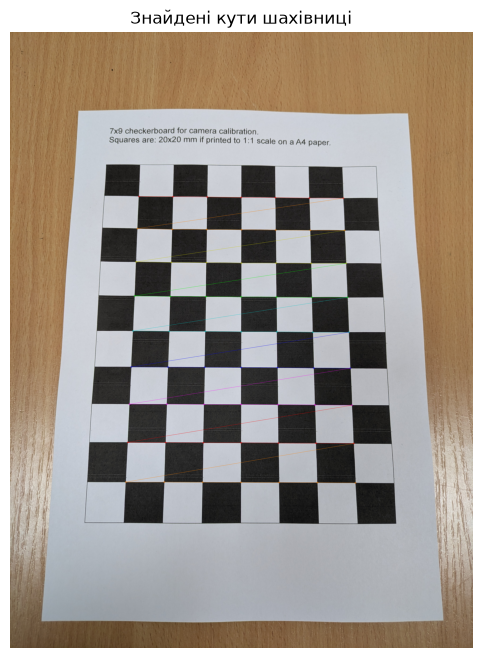

In [47]:
# показати знайдені кути

img = cv2.imread(successful_images[0])

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

ret, corners = cv2.findChessboardCorners(
    gray,
    CHECKERBOARD,
    None
)

corners = cv2.cornerSubPix(
    gray,
    corners,
    (11, 11),
    (-1, -1),
    criteria
)

img_corners = cv2.drawChessboardCorners(
    img,
    CHECKERBOARD,
    corners,
    ret
)

img_corners_rgb = cv2.cvtColor(
    img_corners,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(img_corners_rgb)
plt.axis("off")
plt.title("Знайдені кути шахівниці")
plt.show()

In [48]:
# перевірка кількості точок

print("Кількість внутрішніх кутів:",
      CHECKERBOARD[0] * CHECKERBOARD[1])

print("Очікується:", 63)

print("Кількість успішних фотографій:",
      len(imgpoints))

Кількість внутрішніх кутів: 63
Очікується: 63
Кількість успішних фотографій: 24


In [49]:
# визначення розміру зображення

first_img = cv2.imread(successful_images[0])

gray = cv2.cvtColor(
    first_img,
    cv2.COLOR_BGR2GRAY
)

image_size = gray.shape[::-1]

print("Image size:", image_size)

Image size: (3472, 4624)


In [50]:
# калібрування камери
ret, camera_matrix, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(
    objpoints,
    imgpoints,
    image_size,
    None,
    None
)

print("RMS reprojection error:")
print(ret)

print("\nCamera matrix:")
print(camera_matrix)

print("\nDistortion coefficients:")
print(dist_coeffs)

RMS reprojection error:
5.58355678093693

Camera matrix:
[[3.87792161e+03 0.00000000e+00 2.32002120e+03]
 [0.00000000e+00 3.88271592e+03 1.55241624e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Distortion coefficients:
[[-0.00768741 -0.65057406 -0.01122996  0.01279559  1.07078345]]


In [52]:
# параметри камери

fx = camera_matrix[0, 0]
fy = camera_matrix[1, 1]

cx = camera_matrix[0, 2]
cy = camera_matrix[1, 2]

print(f"fx = {fx:.2f}")
print(f"fy = {fy:.2f}")
print(f"cx = {cx:.2f}")
print(f"cy = {cy:.2f}")

fx = 3877.92
fy = 3882.72
cx = 2320.02
cy = 1552.42


In [53]:
# distortion coefficients

dist = dist_coeffs.ravel()

print("Distortion coefficients:")

for i, value in enumerate(dist):
    print(f"d{i+1} = {value:.8f}")

Distortion coefficients:
d1 = -0.00768741
d2 = -0.65057406
d3 = -0.01122996
d4 = 0.01279559
d5 = 1.07078345


In [55]:
# середня похибка репроєкції

total_error = 0
errors = []

for i in range(len(objpoints)):

    projected_points, _ = cv2.projectPoints(
        objpoints[i],
        rvecs[i],
        tvecs[i],
        camera_matrix,
        dist_coeffs
    )

    error = cv2.norm(
        imgpoints[i],
        projected_points,
        cv2.NORM_L2
    ) / len(projected_points)

    errors.append(error)
    total_error += error

mean_error = total_error / len(objpoints)

print(f"Mean reprojection error: {mean_error:.4f} pixels")

Mean reprojection error: 0.6686 pixels


In [57]:
# похибка для кожного фото

for image_path, error in zip(successful_images, errors):
    print(f"{os.path.basename(image_path):25s} {error:.4f} px")

PXL_20261008_131316787.MP.jpg 1.0794 px
PXL_20261008_131320964.MP.jpg 1.0989 px
PXL_20261008_131326200.MP.jpg 0.9929 px
PXL_20261008_131330469.MP.jpg 0.6583 px
PXL_20261008_131333103.MP.jpg 0.4748 px
PXL_20261008_131338920.MP.jpg 0.5884 px
PXL_20261008_131341016.MP.jpg 0.3405 px
PXL_20261008_131344365.MP.jpg 0.7293 px
PXL_20261008_131350692.MP.jpg 0.8235 px
PXL_20261008_131354601.MP.jpg 0.7777 px
PXL_20261008_131400212.MP.jpg 0.6479 px
PXL_20261008_131405366.MP.jpg 0.5281 px
PXL_20261008_131408764.MP.jpg 0.5460 px
PXL_20261008_131413241.MP.jpg 0.4896 px
PXL_20261008_131417228.MP.jpg 0.6495 px
PXL_20261008_131423235.MP.jpg 0.8010 px
PXL_20261008_131429038.MP.jpg 0.4650 px
PXL_20261008_131431148.MP.jpg 0.4643 px
PXL_20261008_131432769.MP.jpg 0.4090 px
PXL_20261008_131438093.MP.jpg 0.4341 px
PXL_20261008_131440151.MP.jpg 0.4132 px
PXL_20261008_131444663.MP.jpg 0.8259 px
PXL_20261008_131449276.MP.jpg 0.8568 px
PXL_20261008_131452159.MP.jpg 0.9527 px


In [58]:
# найгірше фото

worst_index = np.argmax(errors)

print("Найгірше фото:")
print(successful_images[worst_index])

print(f"Error: {errors[worst_index]:.4f} px")

Найгірше фото:
calibration_images/PXL_20261008_131320964.MP.jpg
Error: 1.0989 px


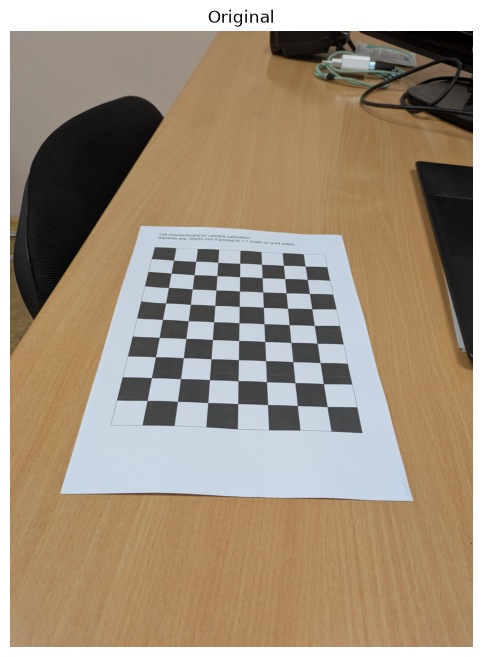

In [60]:
# завантаження тестового фото
test_img = cv2.imread("test.jpg")

if test_img is None:
    raise ValueError("Не знайдено test.jpg")

test_rgb = cv2.cvtColor(
    test_img,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(test_rgb)
plt.axis("off")
plt.title("Original")
plt.show()

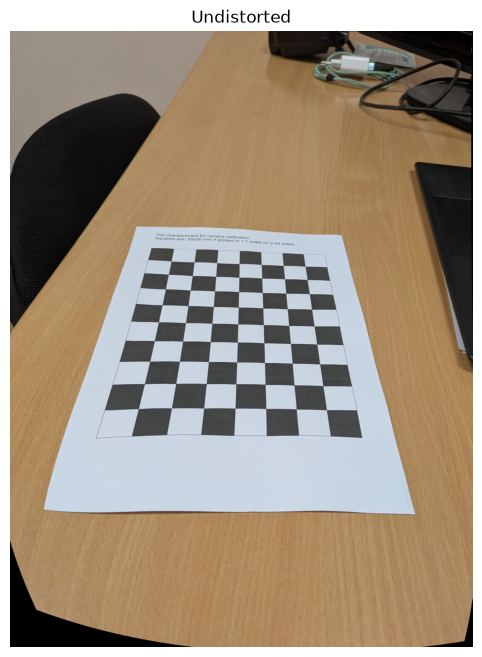

In [61]:
# виправлення distortion

undistorted = cv2.undistort(
    test_img,
    camera_matrix,
    dist_coeffs
)

undistorted_rgb = cv2.cvtColor(
    undistorted,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(undistorted_rgb)
plt.axis("off")
plt.title("Undistorted")
plt.show()

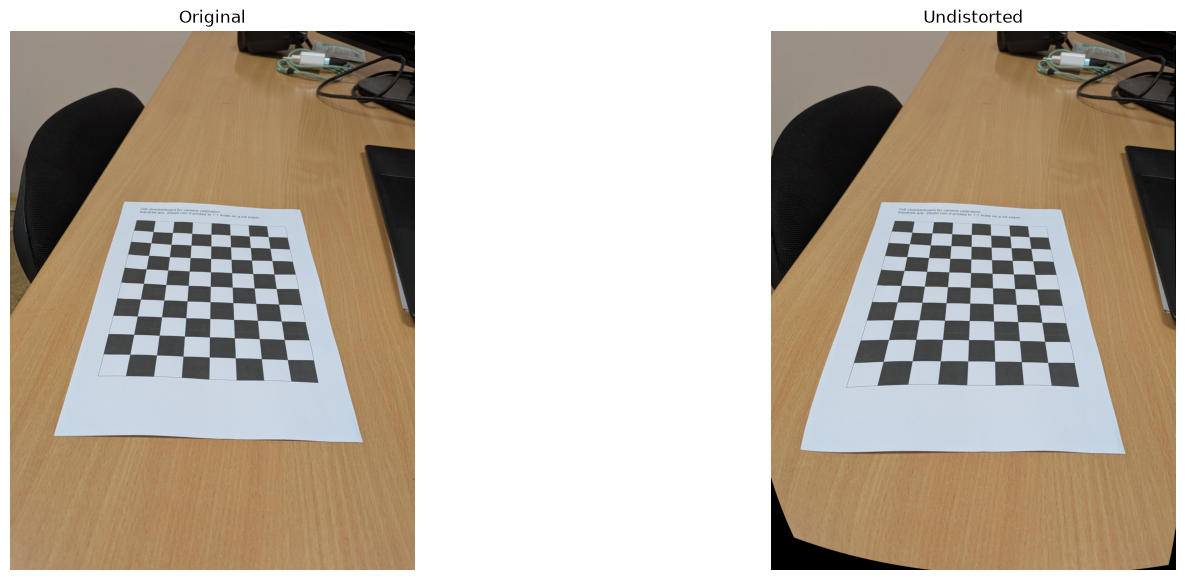

In [62]:
# порівняння Original / Undistorted

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(
    cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(undistorted, cv2.COLOR_BGR2RGB)
)
axes[1].set_title("Undistorted")
axes[1].axis("off")

plt.show()

In [64]:
# оптимальна матриця камери

h, w = test_img.shape[:2]

new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(
    camera_matrix,
    dist_coeffs,
    (w, h),
    1,
    (w, h)
)

print("New camera matrix:")
print(new_camera_matrix)

print("\nROI:")
print(roi)

New camera matrix:
[[3.66812017e+03 0.00000000e+00 2.35336356e+03]
 [0.00000000e+00 3.80070963e+03 1.56729726e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

ROI:
(947, 50, 2431, 3429)


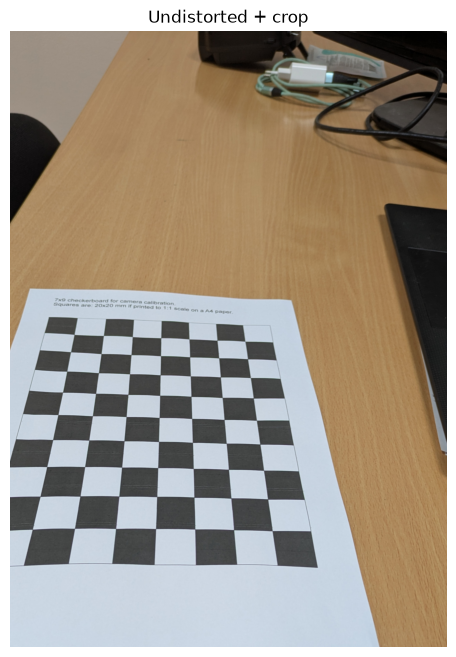

In [65]:
# Undistort + crop

undistorted = cv2.undistort(
    test_img,
    camera_matrix,
    dist_coeffs,
    None,
    new_camera_matrix
)

x, y, w_roi, h_roi = roi

if w_roi > 0 and h_roi > 0:
    undistorted_crop = undistorted[
        y:y+h_roi,
        x:x+w_roi
    ]
else:
    undistorted_crop = undistorted

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(
        undistorted_crop,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("Undistorted + crop")
plt.show()

In [66]:
# зберегти результати калібрування

np.savez(
    "camera_calibration.npz",

    camera_matrix=camera_matrix,

    dist_coeffs=dist_coeffs,

    new_camera_matrix=new_camera_matrix,

    image_width=w,
    image_height=h
)

print("Калібрування збережено:")
print("camera_calibration.npz")

Калібрування збережено:
camera_calibration.npz


In [67]:
# перевірити збережений файл

data = np.load("camera_calibration.npz")

camera_matrix_loaded = data["camera_matrix"]
dist_coeffs_loaded = data["dist_coeffs"]
new_camera_matrix_loaded = data["new_camera_matrix"]

print("Camera matrix:")
print(camera_matrix_loaded)

print("\nDistortion:")
print(dist_coeffs_loaded)

Camera matrix:
[[3.87792161e+03 0.00000000e+00 2.32002120e+03]
 [0.00000000e+00 3.88271592e+03 1.55241624e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Distortion:
[[-0.00768741 -0.65057406 -0.01122996  0.01279559  1.07078345]]


In [68]:
# функція для подальшого використання

def undistort_frame(frame, camera_matrix, dist_coeffs):
    """
    Виправляє distortion кадру.
    """

    return cv2.undistort(
        frame,
        camera_matrix,
        dist_coeffs
    )

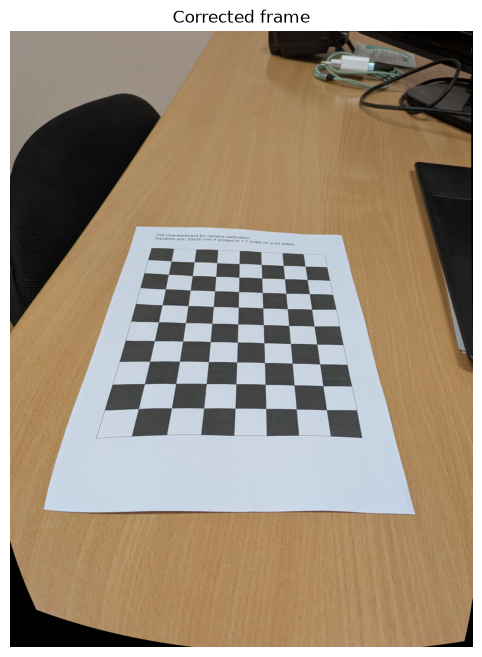

In [69]:
# приклад використання
frame = cv2.imread("test.jpg")

corrected_frame = undistort_frame(
    frame,
    camera_matrix_loaded,
    dist_coeffs_loaded
)

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(
        corrected_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("Corrected frame")
plt.show()